###  MicroGrad demo

In [50]:
import random
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [51]:
from micrograd.engine import Value
from micrograd.nn import Neuron, Layer, MLP

In [52]:
np.random.seed(1337)
random.seed(1337)

In [73]:
# make up a dataset

from sklearn.datasets import make_moons, make_blobs
X, y = make_moons(n_samples=100, noise=0.1)

In [74]:
X

array([[ 1.88101391e+00, -1.16515726e-03],
       [-1.39782923e-01,  1.14462300e+00],
       [-8.70275040e-01,  2.14313054e-01],
       [ 7.52531198e-02, -1.57299703e-01],
       [ 1.75816900e+00, -6.54567021e-02],
       [ 5.89619488e-01, -5.43142576e-01],
       [ 1.17455360e+00, -3.74402988e-01],
       [ 1.55717533e+00, -1.45351957e-03],
       [ 5.51016769e-01, -3.54698720e-01],
       [ 1.30772759e+00, -3.59485643e-01],
       [ 1.84297393e+00,  9.66278034e-02],
       [-8.46668744e-01,  4.33883215e-01],
       [ 1.03844059e+00, -6.65056154e-01],
       [ 2.07264872e+00,  1.85315341e-01],
       [ 4.13003491e-01,  8.52330258e-01],
       [ 3.91762314e-01,  7.53245264e-01],
       [ 2.09362901e+00,  4.29553711e-01],
       [-7.61221370e-01,  6.38084211e-01],
       [ 1.14909996e-01,  9.37173960e-01],
       [ 8.04285249e-01,  6.96928887e-01],
       [ 8.51323720e-01, -6.70863165e-01],
       [ 5.53843397e-01, -3.71388059e-01],
       [ 1.16060562e-01,  3.62644567e-01],
       [ 6.

In [75]:
y

array([1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1,
       1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0,
       0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0])

In [76]:
y = y*2 - 1 # make y be -1 or 1
y

array([ 1, -1, -1,  1,  1,  1,  1,  1,  1,  1,  1, -1,  1,  1, -1, -1,  1,
       -1, -1, -1,  1,  1,  1, -1, -1,  1,  1, -1, -1,  1,  1,  1,  1,  1,
        1,  1, -1, -1, -1,  1,  1,  1,  1,  1,  1,  1,  1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1,  1, -1,  1,  1,  1, -1, -1,  1, -1, -1, -1,
       -1, -1, -1, -1,  1,  1,  1, -1, -1,  1, -1,  1,  1, -1,  1,  1, -1,
        1,  1, -1, -1, -1,  1, -1, -1,  1, -1, -1,  1, -1, -1, -1])

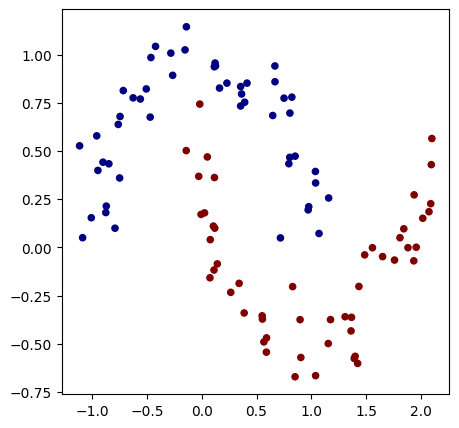

In [77]:
# visualize in 2D
plt.figure(figsize=(5,5))
plt.scatter(X[:,0], X[:,1], c=y, s=20, cmap='jet')

In [54]:
# initialize a model 
model = MLP(2, [16, 16, 1]) # 2-layer neural network
print(model)
print("number of parameters", len(model.parameters()))

MLP of [Layer of [ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2), ReLUNeuron(2)], Layer of [ReLUNeuron(16), ReLUNeuron(16), ReLUNeuron(16), ReLUNeuron(16), ReLUNeuron(16), ReLUNeuron(16), ReLUNeuron(16), ReLUNeuron(16), ReLUNeuron(16), ReLUNeuron(16), ReLUNeuron(16), ReLUNeuron(16), ReLUNeuron(16), ReLUNeuron(16), ReLUNeuron(16), ReLUNeuron(16)], Layer of [LinearNeuron(16)]]
number of parameters 337


In [55]:
# loss function
def loss(batch_size=None):
    
    # inline DataLoader :)
    if batch_size is None:
        Xb, yb = X, y
    else:
        ri = np.random.permutation(X.shape[0])[:batch_size]
        Xb, yb = X[ri], y[ri]
    inputs = [list(map(Value, xrow)) for xrow in Xb]
    
    # forward the model to get scores
    scores = list(map(model, inputs))
    
    # svm "max-margin" loss
    losses = [(1 + -yi*scorei).relu() for yi, scorei in zip(yb, scores)]
    data_loss = sum(losses) * (1.0 / len(losses))
    # L2 regularization
    alpha = 1e-4
    reg_loss = alpha * sum((p*p for p in model.parameters()))
    total_loss = data_loss + reg_loss
    
    # also get accuracy
    accuracy = [(yi > 0) == (scorei.data > 0) for yi, scorei in zip(yb, scores)]
    return total_loss, sum(accuracy) / len(accuracy)

total_loss, acc = loss()
print(total_loss, acc)

Value(data=0.8958441028683222, grad=0) 0.5


In [56]:
# optimization
for k in range(100):
    
    # forward
    total_loss, acc = loss()
    
    # backward
    model.zero_grad()
    total_loss.backward()
    
    # update (sgd)
    learning_rate = 1.0 - 0.9*k/100
    for p in model.parameters():
        p.data -= learning_rate * p.grad
    
    if k % 1 == 0:
        print(f"step {k} loss {total_loss.data}, accuracy {acc*100}%")


step 0 loss 0.8958441028683222, accuracy 50.0%
step 1 loss 1.723590533697202, accuracy 81.0%
step 2 loss 0.742900631385113, accuracy 77.0%
step 3 loss 0.7705641260584202, accuracy 82.0%
step 4 loss 0.3692793385976538, accuracy 84.0%
step 5 loss 0.31354548191852194, accuracy 86.0%
step 6 loss 0.2814234349772434, accuracy 89.0%
step 7 loss 0.26888733313983904, accuracy 91.0%
step 8 loss 0.2567147286057417, accuracy 91.0%
step 9 loss 0.27048625516379227, accuracy 91.0%
step 10 loss 0.2450702385365804, accuracy 91.0%
step 11 loss 0.25099055297915035, accuracy 92.0%
step 12 loss 0.21560951851922946, accuracy 91.0%
step 13 loss 0.23090378446402735, accuracy 93.0%
step 14 loss 0.20152151227899434, accuracy 92.0%
step 15 loss 0.22574506279282233, accuracy 93.0%
step 16 loss 0.19447987596204103, accuracy 92.0%
step 17 loss 0.2108949619924637, accuracy 93.0%
step 18 loss 0.15983077356303593, accuracy 94.0%
step 19 loss 0.18453748746883927, accuracy 93.0%
step 20 loss 0.18977522856087628, accurac

In [57]:
# visualize decision boundary

h = 0.25
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                     np.arange(y_min, y_max, h))


In [58]:
xx

array([[-2.02219391, -1.77219391, -1.52219391, -1.27219391, -1.02219391,
        -0.77219391, -0.52219391, -0.27219391, -0.02219391,  0.22780609,
         0.47780609,  0.72780609,  0.97780609,  1.22780609,  1.47780609,
         1.72780609,  1.97780609,  2.22780609,  2.47780609,  2.72780609,
         2.97780609],
       [-2.02219391, -1.77219391, -1.52219391, -1.27219391, -1.02219391,
        -0.77219391, -0.52219391, -0.27219391, -0.02219391,  0.22780609,
         0.47780609,  0.72780609,  0.97780609,  1.22780609,  1.47780609,
         1.72780609,  1.97780609,  2.22780609,  2.47780609,  2.72780609,
         2.97780609],
       [-2.02219391, -1.77219391, -1.52219391, -1.27219391, -1.02219391,
        -0.77219391, -0.52219391, -0.27219391, -0.02219391,  0.22780609,
         0.47780609,  0.72780609,  0.97780609,  1.22780609,  1.47780609,
         1.72780609,  1.97780609,  2.22780609,  2.47780609,  2.72780609,
         2.97780609],
       [-2.02219391, -1.77219391, -1.52219391, -1.27219391

In [59]:
yy

array([[-1.5486393, -1.5486393, -1.5486393, -1.5486393, -1.5486393,
        -1.5486393, -1.5486393, -1.5486393, -1.5486393, -1.5486393,
        -1.5486393, -1.5486393, -1.5486393, -1.5486393, -1.5486393,
        -1.5486393, -1.5486393, -1.5486393, -1.5486393, -1.5486393,
        -1.5486393],
       [-1.2986393, -1.2986393, -1.2986393, -1.2986393, -1.2986393,
        -1.2986393, -1.2986393, -1.2986393, -1.2986393, -1.2986393,
        -1.2986393, -1.2986393, -1.2986393, -1.2986393, -1.2986393,
        -1.2986393, -1.2986393, -1.2986393, -1.2986393, -1.2986393,
        -1.2986393],
       [-1.0486393, -1.0486393, -1.0486393, -1.0486393, -1.0486393,
        -1.0486393, -1.0486393, -1.0486393, -1.0486393, -1.0486393,
        -1.0486393, -1.0486393, -1.0486393, -1.0486393, -1.0486393,
        -1.0486393, -1.0486393, -1.0486393, -1.0486393, -1.0486393,
        -1.0486393],
       [-0.7986393, -0.7986393, -0.7986393, -0.7986393, -0.7986393,
        -0.7986393, -0.7986393, -0.7986393, -0.798639

In [78]:
Xmesh = np.c_[xx.ravel(), yy.ravel()]

In [79]:
inputs = [list(map(Value, xrow)) for xrow in Xmesh]
scores = list(map(model, inputs))

In [80]:
# Extract the raw numbers from the Value objects
raw_scores = [s.data for s in scores]

print("First 10 raw scores:")
print(raw_scores[:10])


First 10 raw scores:
[-5.1259652189827145, -3.88955871134179, -2.9126815747773995, -2.2507072547897935, -1.7183210097859227, -1.1859347647820515, -0.6515993583989965, 0.11650730597154, 0.759693943293254, 2.4341401458838616]


In [81]:
print("Total rows in Xmesh:", len(Xmesh))
print("Total items in inputs:", len(inputs))
print("Total items in scores:", len(scores))
print("Type of scores:", type(scores))

Total rows in Xmesh: 315
Total items in inputs: 315
Total items in scores: 315
Type of scores: <class 'list'>


In [65]:
Z = np.array([s.data > 0 for s in scores])
Z

array([False, False, False, False, False, False, False,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True, False, False, False, False, False, False,
       False,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True, False, False, False,
       False, False, False, False,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
       False, False, False, False, False, False,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True, False, False, False, False, False, False,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True, False, False, False,
       False, False, False,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
       False, False,

In [66]:
Z = Z.reshape(xx.shape)
Z

array([[False, False, False, False, False, False, False,  True,  True,
         True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True],
       [False, False, False, False, False, False, False,  True,  True,
         True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True],
       [False, False, False, False, False, False, False,  True,  True,
         True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True],
       [False, False, False, False, False, False,  True,  True,  True,
         True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True],
       [False, False, False, False, False, False,  True,  True,  True,
         True,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True],
       [False, False, False, False, False, False,  True,  True,  True,
         True,  True,  True,  True,  True,  True,  True,  True,  True

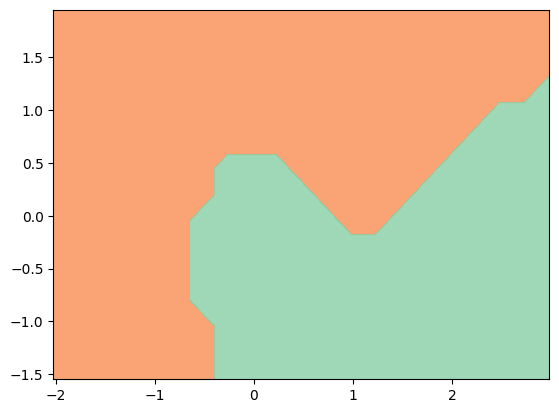

In [68]:
fig = plt.figure()
plt.contourf(xx, yy, Z, cmap=plt.cm.Spectral, alpha=0.8)

(-1.548639298268643, 1.951360701731357)

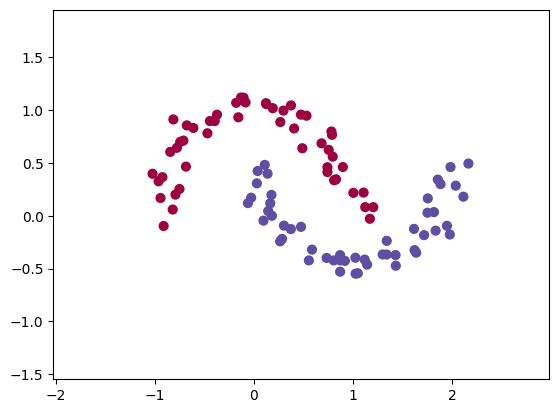

In [69]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=40, cmap=plt.cm.Spectral)
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())